# Moving Average (MA) Models

An MA($q$) process $Y_t=\mu+\varepsilon_t+\theta_1\varepsilon_{t-1}+\dots+\theta_q\varepsilon_{t-q}$ has $\gamma(h)=\sigma^2\sum_{j}\theta_j\theta_{j+h}$ for $h\le q$ and zero beyond, so its ACF cuts off at lag $q$. We compute theoretical values, compare them with a simulation, and then fit an MA model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

rng = np.random.default_rng(40)

def ma_acvf(theta, sigma2=1.0, max_lag=6):
    c = np.r_[1.0, theta]
    q = len(c) - 1
    return np.array([sigma2 * np.dot(c[:q + 1 - h], c[h:]) if h <= q else 0.0 for h in range(max_lag + 1)])

g = ma_acvf([0.5])
print("MA(1) theta=0.5  gamma:", g[:3], " rho(1) =", g[1] / g[0])
g2 = ma_acvf([0.7, -0.35])
print("MA(2) theta=(0.7,-0.35) rho:", np.round(g2[:5] / g2[0], 4))

MA(1) theta=0.5  gamma: [1.25 0.5  0.  ]  rho(1) = 0.4
MA(2) theta=(0.7,-0.35) rho: [ 1.      0.2822 -0.2171  0.      0.    ]


The MA(1) values match the note: $\gamma(0)=1.25$, $\gamma(1)=0.5$, $\rho(1)=0.4$. For the MA(2), $\rho(1)=(0.7-0.245)/(1+0.49+0.1225)=0.2822$ and $\rho(2)=-0.35/1.6125=-0.2171$.

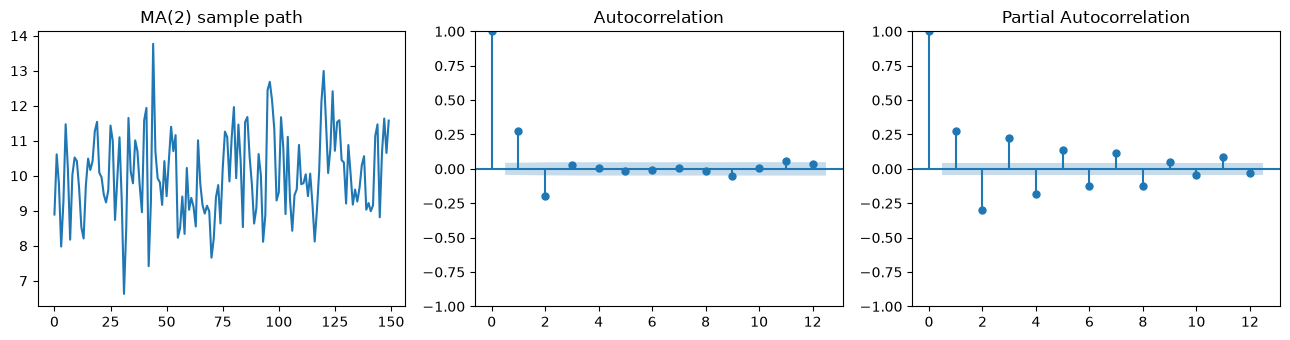

sample rho  : [ 1.     0.278 -0.2    0.031  0.008]
theory rho  : [ 1.     0.282 -0.217  0.     0.   ]


In [2]:
n = 2000
theta = np.array([0.7, -0.35])
eps = rng.normal(size=n + 2)
y = 10 + eps[2:] + theta[0] * eps[1:-1] + theta[1] * eps[:-2]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(y[:150]); ax[0].set_title("MA(2) sample path")
plot_acf(y, lags=12, ax=ax[1]); plot_pacf(y, lags=12, ax=ax[2], method="ywm")
plt.tight_layout(); plt.show()

yc = y - y.mean()
r = [np.sum(yc[h:] * yc[:n - h]) / np.sum(yc ** 2) for h in range(5)]
print("sample rho  :", np.round(r, 3))
print("theory rho  :", np.round(g2[:5] / g2[0], 3))

The sample ACF is close to theory at lags 1 and 2 and fluctuates around zero afterwards (within about $\pm1.96/\sqrt n=\pm0.044$), while the PACF tails off rather than cutting off.

In [3]:
# Shock response of an MA(2): the impulse response is just (1, theta_1, theta_2, 0, ...)
imp = np.zeros(8); imp[0] = 1.0
resp = np.convolve(imp, np.r_[1.0, theta])[:8]
print("response to a unit shock:", resp)

# Fit and compare orders
for q in (1, 2, 3):
    res = ARIMA(y, order=(0, 0, q)).fit()
    print(f"MA({q}): AIC={res.aic:8.1f}  BIC={res.bic:8.1f}")
best = ARIMA(y, order=(0, 0, 2)).fit()
print(best.params.round(3))

response to a unit shock: [ 1.    0.7  -0.35  0.    0.    0.    0.    0.  ]


MA(1): AIC=  6157.7  BIC=  6174.5


MA(2): AIC=  5935.8  BIC=  5958.2


MA(3): AIC=  5934.9  BIC=  5962.9


[ 9.99   0.619 -0.334  1.133]


BIC clearly picks MA(2); AIC is essentially tied between MA(2) and MA(3) (a difference of under one point), so parsimony favours MA(2). The estimates are roughly $\mu=10$, $\theta=(0.7,-0.35)$ up to sampling error. The criteria are only comparable because all models are fitted to the same data.

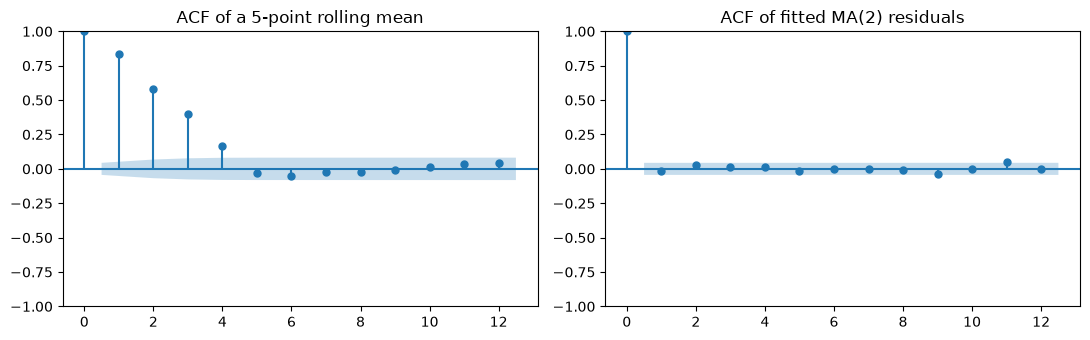

In [4]:
# A rolling mean is NOT an MA model: smooth the same series with a 5-point window
roll = np.convolve(y, np.ones(5) / 5, mode="valid")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
plot_acf(roll, lags=12, ax=ax[0]); ax[0].set_title("ACF of a 5-point rolling mean")
plot_acf(best.resid, lags=12, ax=ax[1]); ax[1].set_title("ACF of fitted MA(2) residuals")
plt.tight_layout(); plt.show()

The rolling mean manufactures autocorrelation out to lag 4 (an artefact of overlapping windows), whereas the residuals of the correctly specified MA(2) are essentially white.